# 07 — Behavioral Metrics

Goes beyond average return. For each method-env pair, report:
- **Success rate**: fraction of greedy rollouts that reach the goal
- **Steps to goal**: how efficient is the learned policy
- **Cliff falls**: how often the policy falls off the cliff (safety)
- **Regret to convergence**: cumulative reward lost during learning

These give a richer picture of what each method *actually learns*, not
just its final reward. Two methods with the same return but different
fall rates have meaningfully different policies.


In [1]:
import sys, os, time
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt

from envs import (CliffWalking, StochasticCliff,
                  CorridorCliff, StochasticCorridorCliff)
from agents import (run_sarsa, run_q_learning, run_expected_sarsa,
                    run_double_expected_sarsa, run_rr_expected_sarsa)
from utils import (multi_seed_run, smooth,
                   bootstrap_mean_ci, bootstrap_diff_ci, pairwise_table,
                   rollout_metrics, regret_to_convergence)

# ---- Run configuration ----
# Set N_RUNS=50 for pilot, bump to 500 for final overnight run
N_RUNS = 50
N_EPISODES = 100
EPS_DEFAULT = 0.1
ALPHA_DEFAULT = 0.3
SLIP = 0.2
RR_DELTA = 1.0   # RR-ES regret threshold used in most experiments

def sem(arr, axis=0):
    return arr.std(axis=axis, ddof=1) / np.sqrt(arr.shape[axis])

# ---- Environment factories ----
def env_det(seed=None):   return CliffWalking()
def env_stoch(seed=None): return StochasticCliff(slip_prob=SLIP, rng_seed=seed)
def env_corr(seed=None):  return CorridorCliff()
def env_scor(seed=None):  return StochasticCorridorCliff(slip_prob=SLIP, rng_seed=seed)

ENVS = {
    'Det Cliff':        env_det,
    'Stoch Cliff':      env_stoch,
    'Corr Cliff':       env_corr,
    'Stoch Corr Cliff': env_scor,
}

# ---- Method registry ----
METHODS = {
    'SARSA':          (run_sarsa,                {}),
    'Q-learning':     (run_q_learning,           {}),
    'Expected SARSA': (run_expected_sarsa,       {}),
    'Double ES':      (run_double_expected_sarsa, {}),
    f'RR-ES (δ={RR_DELTA})': (run_rr_expected_sarsa, {'delta': RR_DELTA}),
}

METHOD_COLORS = {
    'SARSA':              '#1f77b4',
    'Q-learning':         '#ff7f0e',
    'Expected SARSA':     '#2ca02c',
    'Double ES':          '#9467bd',
    f'RR-ES (δ={RR_DELTA})': '#d62728',
}
METHOD_MARKERS = {
    'SARSA':              'o',
    'Q-learning':         's',
    'Expected SARSA':     '^',
    'Double ES':          'v',
    f'RR-ES (δ={RR_DELTA})': 'D',
}

# Train each method for longer on each env, single seed per run,
# but average behavioral metrics across runs.
N_TRAIN_EP = 200
N_METRICS_RUNS = 30  # fewer runs, since each includes a 50-rollout eval
N_ROLLOUTS = 50


In [2]:
def run_one_behavioral(env_fn, fn, kw, alpha, eps, train_ep, seed):
    env = env_fn(seed=seed) if 'seed' in env_fn.__code__.co_varnames else env_fn()
    Q, returns = fn(env, train_ep, alpha=alpha, eps=eps, seed=seed, **kw)
    metrics = rollout_metrics(env_fn, Q, n_rollouts=N_ROLLOUTS, seed=seed + 1000)
    reg = regret_to_convergence(returns, threshold_frac=0.9, window=10)
    return metrics, reg

all_metrics = {env_name: {m_name: [] for m_name in METHODS} for env_name in ENVS}

t0 = time.time()
for env_name, env_fn in ENVS.items():
    print(f'\n=== {env_name} ===')
    for m_name, (fn, kw) in METHODS.items():
        for seed in range(N_METRICS_RUNS):
            metrics, reg = run_one_behavioral(
                env_fn, fn, kw, ALPHA_DEFAULT, EPS_DEFAULT, N_TRAIN_EP, seed)
            all_metrics[env_name][m_name].append({**metrics, **reg})
        print(f'  {m_name}: success={np.mean([m["success_rate"] for m in all_metrics[env_name][m_name]]):.2f}  '
              f'falls={np.mean([m["falls_mean"] for m in all_metrics[env_name][m_name]]):.2f}  '
              f'steps={np.mean([m["steps_mean"] for m in all_metrics[env_name][m_name]]):.1f}')
print(f'\ntotal: {time.time()-t0:.0f}s')



=== Det Cliff ===
  SARSA: success=0.83  falls=0.00  steps=97.4
  Q-learning: success=1.00  falls=0.00  steps=13.0
  Expected SARSA: success=0.97  falls=0.00  steps=31.2
  Double ES: success=0.60  falls=0.00  steps=210.2
  RR-ES (δ=1.0): success=1.00  falls=0.00  steps=13.0

=== Stoch Cliff ===
  SARSA: success=1.00  falls=0.23  steps=37.7
  Q-learning: success=0.96  falls=0.26  steps=56.8
  Expected SARSA: success=1.00  falls=0.17  steps=42.7
  Double ES: success=0.98  falls=0.33  steps=58.7
  RR-ES (δ=1.0): success=0.98  falls=0.26  steps=52.8

=== Corr Cliff ===
  SARSA: success=0.93  falls=0.00  steps=43.9
  Q-learning: success=1.00  falls=0.00  steps=11.0
  Expected SARSA: success=0.93  falls=0.00  steps=43.6
  Double ES: success=0.67  falls=0.00  steps=174.2
  RR-ES (δ=1.0): success=1.00  falls=0.00  steps=11.0

=== Stoch Corr Cliff ===
  SARSA: success=1.00  falls=0.11  steps=26.3
  Q-learning: success=1.00  falls=0.07  steps=22.1
  Expected SARSA: success=1.00  falls=0.06  ste

In [3]:
# Build summary table
import pandas as pd

rows = []
for env_name, env_res in all_metrics.items():
    for m_name, runs in env_res.items():
        succ = np.mean([r['success_rate'] for r in runs])
        falls = np.mean([r['falls_mean'] for r in runs])
        falls_sem = np.std([r['falls_mean'] for r in runs]) / np.sqrt(len(runs))
        steps = np.mean([r['steps_mean'] for r in runs])
        steps_sem = np.std([r['steps_mean'] for r in runs]) / np.sqrt(len(runs))
        reg = np.mean([r['regret'] for r in runs])
        reg_sem = np.std([r['regret'] for r in runs]) / np.sqrt(len(runs))
        rows.append({
            'env': env_name, 'method': m_name,
            'success_rate': f'{succ:.2f}',
            'falls_mean': f'{falls:.2f}±{falls_sem:.2f}',
            'steps_mean': f'{steps:.1f}±{steps_sem:.1f}',
            'regret': f'{reg:.0f}±{reg_sem:.0f}',
        })
df = pd.DataFrame(rows)
print(df.to_string(index=False))
df.to_csv('../results/data/07_behavioral_metrics.csv', index=False)
print('\nsaved to CSV')


             env         method success_rate falls_mean steps_mean     regret
       Det Cliff          SARSA         0.83  0.00±0.00  97.4±32.9   6362±192
       Det Cliff     Q-learning         1.00  0.00±0.00   13.0±0.0   4722±175
       Det Cliff Expected SARSA         0.97  0.00±0.00  31.2±15.9   5518±134
       Det Cliff      Double ES         0.60  0.00±0.00 210.2±43.2   9206±501
       Det Cliff  RR-ES (δ=1.0)         1.00  0.00±0.00   13.0±0.0   4946±300
     Stoch Cliff          SARSA         1.00  0.23±0.06   37.7±3.8  15116±936
     Stoch Cliff     Q-learning         0.96  0.26±0.08  56.8±17.2  12687±640
     Stoch Cliff Expected SARSA         1.00  0.17±0.05   42.7±6.3  12450±636
     Stoch Cliff      Double ES         0.98  0.33±0.11  58.7±13.9 18502±1019
     Stoch Cliff  RR-ES (δ=1.0)         0.98  0.26±0.08  52.8±13.3  13990±687
      Corr Cliff          SARSA         0.93  0.00±0.00  43.9±22.3   8770±149
      Corr Cliff     Q-learning         1.00  0.00±0.00   11.0±0

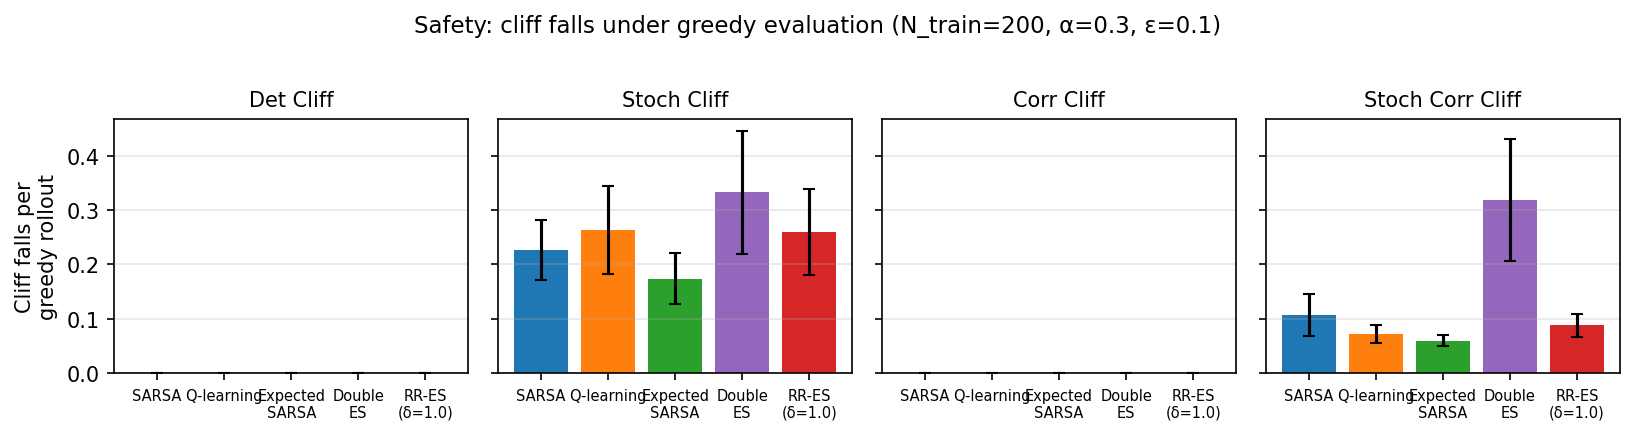

In [4]:
# Barplot: cliff falls by method per env (safety metric)
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), dpi=150, sharey=True)
for ax, (env_name, env_res) in zip(axes, all_metrics.items()):
    falls_mean = [np.mean([r['falls_mean'] for r in runs]) for runs in env_res.values()]
    falls_sem  = [np.std([r['falls_mean'] for r in runs]) / np.sqrt(len(runs)) for runs in env_res.values()]
    names = list(env_res.keys())
    colors = [METHOD_COLORS[n] for n in names]
    xs = np.arange(len(names))
    ax.bar(xs, falls_mean, yerr=falls_sem, color=colors, capsize=3)
    ax.set_xticks(xs)
    ax.set_xticklabels([n.replace(' ', '\n') for n in names], fontsize=7, rotation=0)
    ax.set_title(env_name, fontsize=10)
    ax.grid(alpha=0.3, axis='y')
axes[0].set_ylabel('Cliff falls per\ngreedy rollout')
plt.suptitle(f'Safety: cliff falls under greedy evaluation (N_train={N_TRAIN_EP}, α={ALPHA_DEFAULT}, ε={EPS_DEFAULT})',
             y=1.02, fontsize=11)
plt.tight_layout()
plt.savefig('../results/figures/07_cliff_falls.png', dpi=200, bbox_inches='tight')
plt.show()
